STUDENT PERFORMANCE PREDICTION
USING MACHINE LEARNING

Subject: Artificial Intelligence
Language: Python
Platform: Google Colab

Objective:
To predict students' final academic
marks using machine learning algorithms.

In [63]:
print("Student Performance Prediction Project")
print("Notebook saved successfully!")

Student Performance Prediction Project
Notebook saved successfully!


In [64]:
# Import Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

# Import machine learning tools

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All Python libraries imported successfully!")

All Python libraries imported successfully!


In [65]:
# Download Student Performance Dataset

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url)
response.raise_for_status()

# Open the downloaded ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:

    # Check whether another ZIP is inside
    if "student.zip" in outer_zip.namelist():

        inner_zip = zipfile.ZipFile(
            io.BytesIO(outer_zip.read("student.zip"))
        )

        df = pd.read_csv(
            inner_zip.open("student-mat.csv"),
            sep=";"
        )

    else:
        # If CSV files are directly available
        file_name = next(
            f for f in outer_zip.namelist()
            if f.endswith("student-mat.csv")
        )

        df = pd.read_csv(
            outer_zip.open(file_name),
            sep=";"
        )

print("Dataset downloaded successfully!")
print("Total students:", len(df))
print("Total columns:", len(df.columns))

Dataset downloaded successfully!
Total students: 395
Total columns: 33


In [66]:
# Display first five student records

display(df.head())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [67]:
# Check dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (395, 33)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Missing Values:
0

Statistical Summary:


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


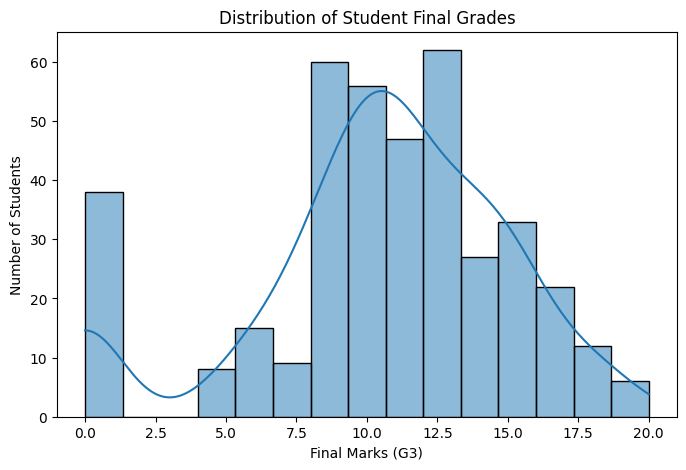

In [68]:
plt.figure(figsize=(8,5))

sns.histplot(df["G3"], bins=15, kde=True)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Marks (G3)")
plt.ylabel("Number of Students")

plt.show()

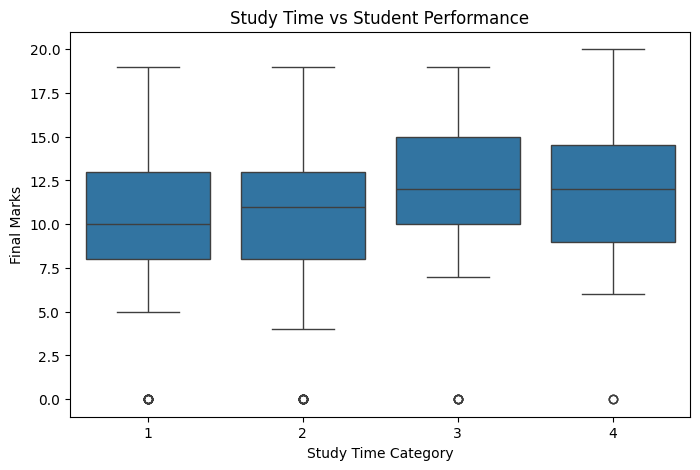

In [69]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="studytime",
    y="G3",
    data=df
)

plt.title("Study Time vs Student Performance")
plt.xlabel("Study Time Category")
plt.ylabel("Final Marks")

plt.show()

In [70]:
# Select input and output variables

X = df.drop(columns=["G1", "G2", "G3"])

y = df["G3"]

print("Input data shape:", X.shape)
print("Output data shape:", y.shape)

Input data shape: (395, 30)
Output data shape: (395,)


In [71]:
# Identify numerical columns

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),

    ("cat",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

print("Data preprocessing completed!")

Data preprocessing completed!


In [72]:
# Split dataset into training and testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 316
Testing records: 79


In [73]:
# Create machine learning models

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        random_state=42
    )
}

results = []
trained_models = {}

# Train and test each model

for name, algorithm in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(
        y_test, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    results.append([name, mae, rmse, r2])

    trained_models[name] = model

# Display comparison

results_df = pd.DataFrame(
    results,
    columns=["Algorithm", "MAE", "RMSE", "R2 Score"]
)

display(results_df.round(3))

,Algorithm,MAE,RMSE,R2 Score
0,Linear Regression,3.395,4.196,0.141
1,Decision Tree,3.633,4.838,-0.141
2,Random Forest,3.002,3.769,0.307


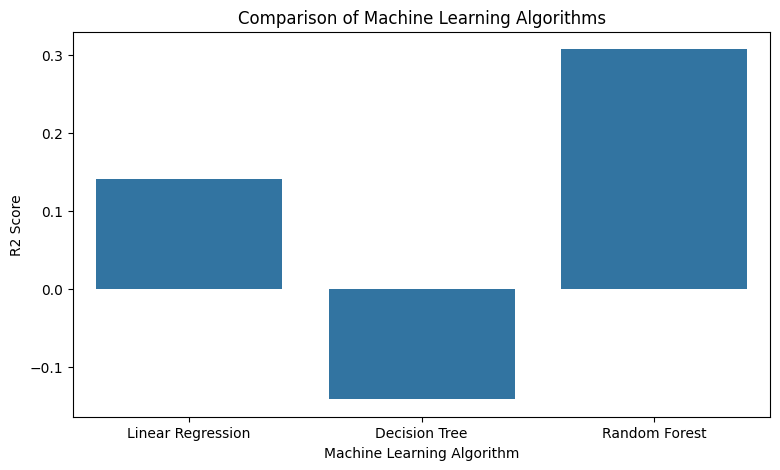

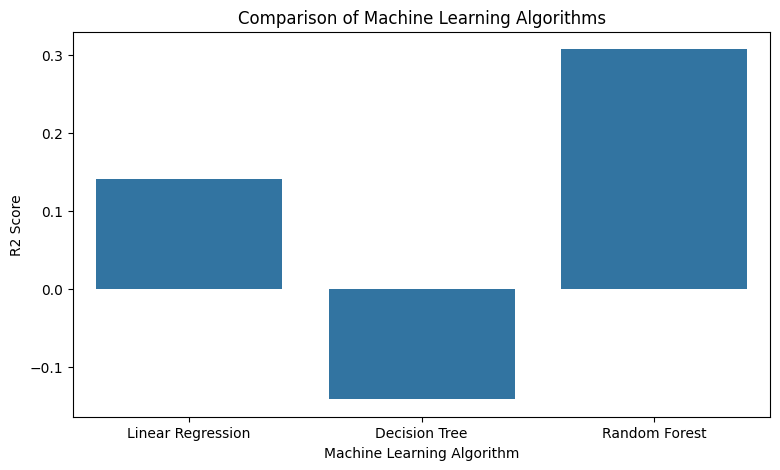

In [75]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="R2 Score"
)

plt.title("Comparison of Machine Learning Algorithms")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("R2 Score")

plt.show()

In [76]:
# Create Random Forest pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

# Parameters to test

parameters = {
    "model__n_estimators": [50, 100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5]
}

# Apply Grid Search

grid_search = GridSearchCV(
    rf_pipeline,
    parameters,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Select best model

best_model = grid_search.best_estimator_

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation MAE:")
print(round(-grid_search.best_score_, 3))

Best Parameters:
{'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 50}

Best Cross Validation MAE:
2.899


In [77]:
# Predict using optimized model

optimized_predictions = best_model.predict(X_test)

# Calculate evaluation metrics

mae = mean_absolute_error(
    y_test, optimized_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, optimized_predictions)
)

r2 = r2_score(
    y_test, optimized_predictions
)

print("OPTIMIZED RANDOM FOREST RESULTS")

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

OPTIMIZED RANDOM FOREST RESULTS
MAE: 3.025
RMSE: 3.801
R2 Score: 0.295


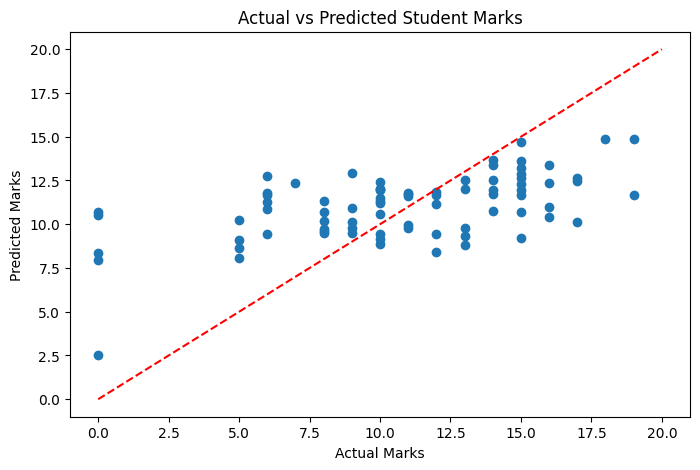

In [78]:
plt.figure(figsize=(8,5))

plt.scatter(
    y_test,
    optimized_predictions
)

plt.plot(
    [0,20],
    [0,20],
    "r--"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.title("Actual vs Predicted Student Marks")

plt.show()

In [79]:
# Select one student

sample_student = X_test.iloc[[0]]

# Predict marks

prediction = best_model.predict(sample_student)

print("STUDENT DETAILS")

print("Age:",
      sample_student["age"].values[0])

print("Study Time:",
      sample_student["studytime"].values[0])

print("Absences:",
      sample_student["absences"].values[0])

print("\nPredicted Final Marks:",
      round(prediction[0], 2), "/20")

STUDENT DETAILS
Age: 17
Study Time: 1
Absences: 2

Predicted Final Marks: 9.43 /20


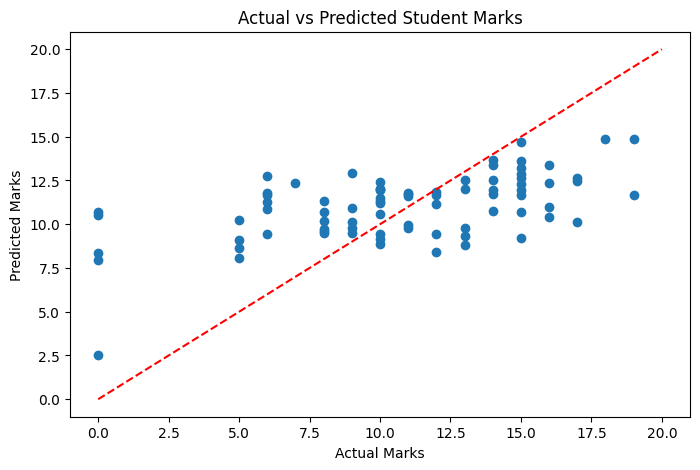

In [80]:
plt.figure(figsize=(8,5))

plt.scatter(
    y_test,
    optimized_predictions
)

plt.plot(
    [0,20],
    [0,20],
    "r--"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

plt.title("Actual vs Predicted Student Marks")

plt.show()